# Impute data using MAGIC

In [2]:
import scanpy as sc
import h5py as hp
import magic
import scprep

import mygene
def match_genes_to_reference(query_genes, ref_genes):
    """
    将查询基因名称匹配到参考基因名称
    
    参数:
        query_genes: 需要匹配的基因列表
        ref_genes: 参考基因列表
        
    返回:
        字典: {查询基因: 匹配到的参考基因}，未能匹配的返回nan
    """
    # 初始化mygene客户端
    mg = mygene.MyGeneInfo()
    
    # 首先检查直接匹配
    matched = {}
    unmatched = []
    ref_set = set(ref_genes)
    
    for gene in query_genes:
        if gene in ref_set:
            matched[gene] = gene
        else:
            unmatched.append(gene)
    
    # 对未匹配的基因进行查询
    if unmatched:
        # 扩展检索范围，包括别名、以前名称等
        results = mg.querymany(unmatched, 
                              scopes=['symbol', 'alias', 'prev_symbol', 'name'],
                              fields='symbol',
                              species='human')
        
        for res in results:
            query_gene = res['query']
            # 检查是否查询成功且有symbol字段
            if 'symbol' in res:
                # 检查symbol是否在参考集中
                if res['symbol'] in ref_set:
                    matched[query_gene] = res['symbol']
                # 如果没有直接匹配，检查是否有其他别名匹配
                elif 'alias' in res:
                    for alias in res['alias']:
                        if alias in ref_set:
                            matched[query_gene] = alias
                            break
                # 检查以前名称是否匹配
                elif 'prev_symbol' in res and res['prev_symbol'] in ref_set:
                    matched[query_gene] = res['prev_symbol']
            # 如果以上都未匹配，则返回nan
            if query_gene not in matched:
                matched[query_gene] = '<unk>'
                # matched[query_gene] = np.nan
    
    return matched

## A549

In [2]:
a549_cell_line = sc.read_10x_mtx('./GSE272070_RAW',prefix='GSM8392460_Cal07_mock_')
a549_cell_line1 = sc.read_10x_mtx('./GSE272070_RAW',prefix='GSM8392468_Perth09_mock_')
a549_cell_line = sc.concat([a549_cell_line, a549_cell_line1])
a549_cell_line.var = a549_cell_line1.var
a549_cell_line.var['gene_name'] = a549_cell_line.var.index.values
# a549_cell_line.write_h5ad('./a549_cell_line.h5ad')
emt_data = a549_cell_line.to_df()

/home/yimiaofeng/anaconda3/envs/dotsl/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


/home/yimiaofeng/anaconda3/envs/dotsl/lib/python3.10/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: xlabel='Library size', ylabel='Number of cells'>

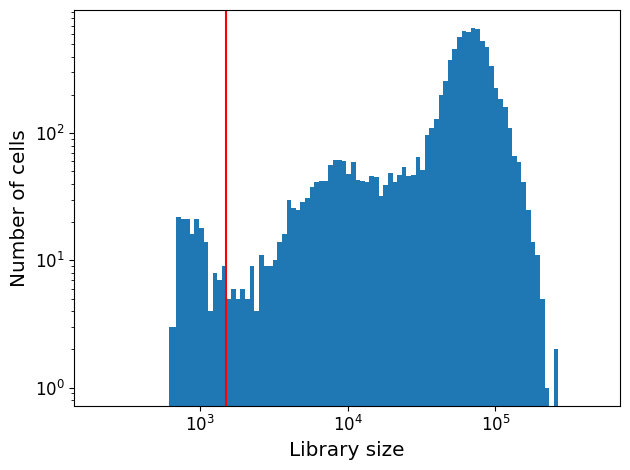

In [3]:
scprep.plot.plot_library_size(emt_data, cutoff=1500)

In [4]:
emt_data = scprep.filter.filter_library_size(emt_data, cutoff=1500)
emt_data.head()

,RP11-34P13.3,FAM138A,OR4F5,RP11-34P13.7,RP11-34P13.8,RP11-34P13.14,RP11-34P13.9,FO538757.3,FO538757.2,AP006222.2,...,AC213203.1,FAM231B,PB2,PB1,PA,HA,NP,NA.,M,NS
AAACCCACAACCGCTG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACCCACATAACAGA-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACCCAGTCACCTTC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,4.0,0.0,5.0,2.0
AAACCCATCCGAGAAG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACGAAAGAGAAGGT-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
emt_data = scprep.normalize.library_size_normalize(emt_data)
# be sure to uncomment this, unless your data is pre-transformed
emt_data = scprep.transform.sqrt(emt_data)
emt_data.head()

,RP11-34P13.3,FAM138A,OR4F5,RP11-34P13.7,RP11-34P13.8,RP11-34P13.14,RP11-34P13.9,FO538757.3,FO538757.2,AP006222.2,...,AC213203.1,FAM231B,PB2,PB1,PA,HA,NP,NA.,M,NS
AAACCCACAACCGCTG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.400915,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0000
AAACCCACATAACAGA-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0000
AAACCCAGTCACCTTC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.580464,1.160928,0.0,1.297957,0.8209
AAACCCATCCGAGAAG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.289314,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0000
AAACGAAAGAGAAGGT-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.710597,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0000


In [6]:
magic_op = magic.MAGIC()
emt_magic = magic_op.fit_transform(emt_data)

Calculating MAGIC...
  Running MAGIC on 8498 cells and 33702 genes.
  Calculating graph and diffusion operator...


/home/yimiaofeng/.local/lib/python3.10/site-packages/magic/magic.py:425: UserWarning: Input matrix contains unexpressed genes. Please remove them prior to running MAGIC.
  warnings.warn(


    Calculating PCA...
    Calculated PCA in 5.10 seconds.
    Calculating KNN search...
    Calculated KNN search in 8.07 seconds.
    Calculating affinities...


/home/yimiaofeng/.local/lib/python3.10/site-packages/graphtools/graphs.py:290: RuntimeWarning: Detected zero distance between 12 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    Calculated affinities in 8.02 seconds.
  Calculated graph and diffusion operator in 21.67 seconds.
  Running MAGIC with `solver='exact'` on 33702-dimensional data may take a long time. Consider denoising specific genes with `genes=<list-like>` or using `solver='approximate'`.
  Calculating imputation...
  Calculated imputation in 8.90 seconds.
Calculated MAGIC in 31.09 seconds.


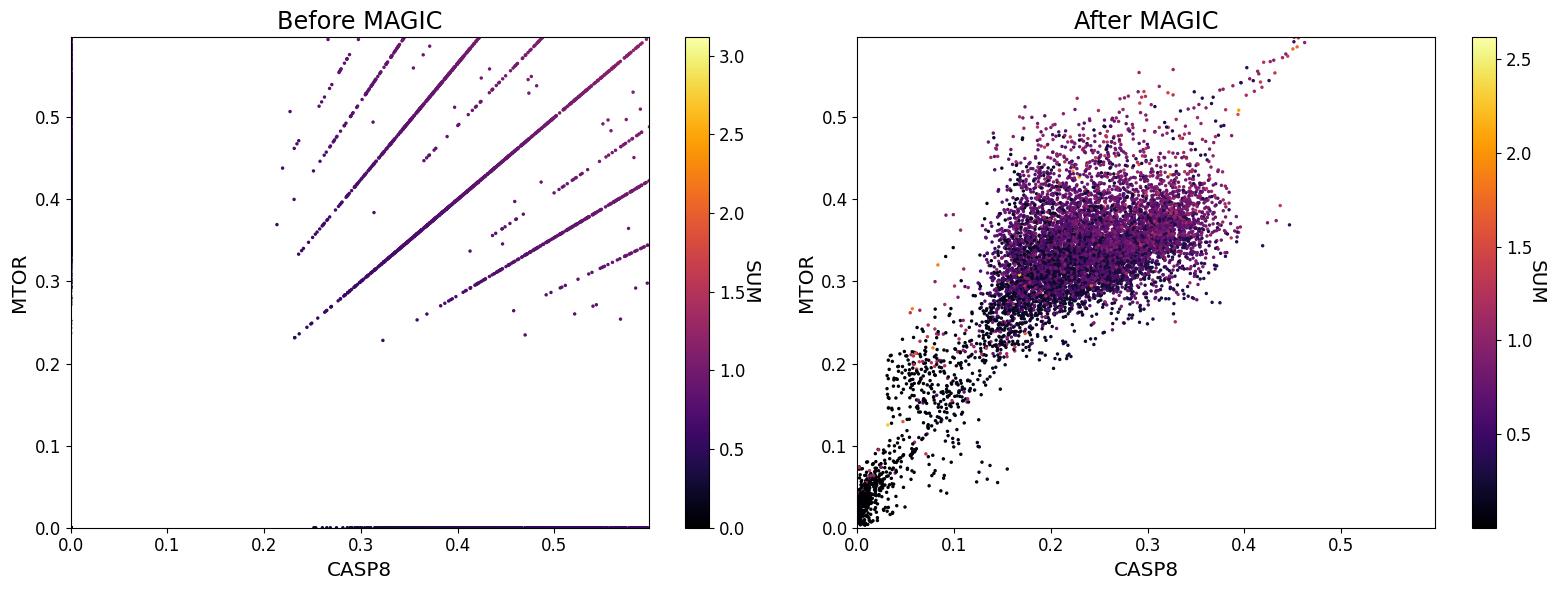

In [18]:
import matplotlib
import matplotlib.pyplot as plt

# Matplotlib command for Jupyter notebooks only
%matplotlib inline

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(16, 6))
g1 = 'CASP8'
g2 = 'MTOR'

# 计算x和y轴的最大值
x_max = max(emt_magic[g1].max(), emt_magic[g2].max())
y_max = max(emt_magic[g2].max(), emt_magic[g1].max())
# x_max = max(emt_data[g1].max(), emt_magic[g1].max())
# y_max = max(emt_data[g2].max(), emt_magic[g2].max())

scprep.plot.scatter(x=emt_data[g1], y=emt_data[g2], c=emt_data[g1]+emt_data[g2],  ax=ax1,
                    xlabel=g1, ylabel=g2, legend_title="SUM", title='Before MAGIC')
ax1.set_xlim(0, x_max)
ax1.set_ylim(0, y_max)

scprep.plot.scatter(x=emt_magic[g1], y=emt_magic[g2], c=emt_magic[g1]+emt_data[g2], ax=ax2,
                    xlabel=g1, ylabel=g2, legend_title="SUM", title='After MAGIC')
ax2.set_xlim(0, x_max)
ax2.set_ylim(0, y_max)

plt.tight_layout()
plt.show()

In [22]:
a549_cell_line_imputed = sc.AnnData(emt_magic)
a549_cell_line_imputed.var = a549_cell_line.var
a549_cell_line_imputed.write_h5ad('./a549_cell_line_imputed.h5ad')

/home/yimiaofeng/anaconda3/envs/dotsl/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


## K562

In [16]:
K562_essential_raw = sc.read_h5ad('/home/yimiaofeng/MyProject/Cancerformer/scCancerPert/K562/K562_essential_raw_singlecell_01.h5ad')
K562_essential_raw = K562_essential_raw[K562_essential_raw.obs['gene']=='non-targeting']
K562_essential_raw.write_h5ad('./K562_cell_line.h5ad')

In [ ]:
import pandas as pd
import pickle as pkl
k562_label = pd.read_csv('./K562_filtered_NP1_F.csv')
k562_gene = set(k562_label['gene_1']).union(set(k562_label['gene_2']))
print(len(k562_gene))

593
593


In [33]:
id_map = match_genes_to_reference(k562_gene, adata.var['gene_name'])

Input sequence provided is already in string format. No operation performed
36 input query terms found dup hits:	[('DDR1', 8), ('DBH', 5), ('PIK3C2B', 3), ('CSF1R', 5), ('NR5A1', 2), ('EGFR', 6), ('ALK', 3), ('CDK


In [41]:
filtered_id_map = {}
for k,v in id_map.items():
    if v=='<unk>':
        filtered_id_map[k]=v

In [ ]:
K562_cell_line = sc.read_h5ad('K562_cell_line.h5ad')
K562_cell_line.var.index = K562_cell_line.var['gene_name'].values
emt_data = K562_cell_line.to_df()
for gene in filtered_id_map.keys():
    if gene not in emt_data.columns:
        emt_data[gene] = 0
emt_data

,LINC01409,LINC01128,NOC2L,KLHL17,HES4,ISG15,SDF4,B3GALT6,UBE2J2,ACAP3,...,PTPRE,HCRTR1,MAP3K5,PRODH,MAPK8IP1,NT5M,PTGIR,CRYBB1,IL12A,FGFR2
cell_barcode,,,,,,,,,,,,,,,,,,,,,
AAACCCAAGCGAGGAG-47,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
AAACCCAAGCGTCTGC-27,0.0,0.0,2.0,0.0,0.0,0.0,2.0,0.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
AAACCCAAGGAGGGTG-47,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
AAACCCAAGTACCCTA-20,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
AAACCCAAGTGTTCAC-3,1.0,0.0,2.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTTGGTCGGCCTA-1,0.0,0.0,7.0,0.0,0.0,1.0,3.0,0.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
TTTGTTGGTCGTCTCT-6,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
TTTGTTGGTGCTATTG-36,0.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


/home/yimiaofeng/anaconda3/envs/dotsl/lib/python3.10/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Axes: xlabel='Library size', ylabel='Number of cells'>

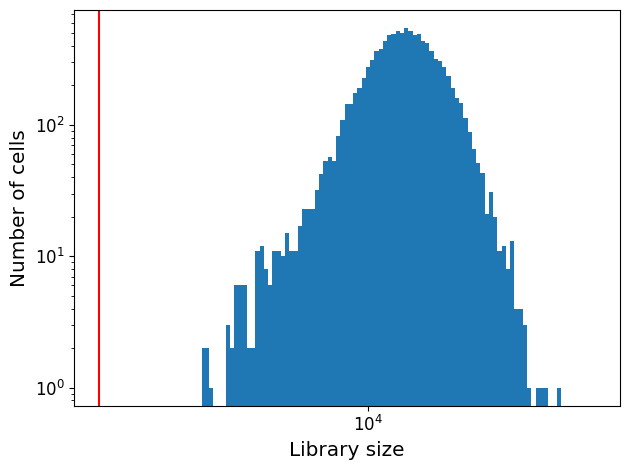

In [43]:
scprep.plot.plot_library_size(emt_data, cutoff=1500)

In [44]:
emt_data = scprep.filter.filter_library_size(emt_data, cutoff=1500)
emt_data.head()

,LINC01409,LINC01128,NOC2L,KLHL17,HES4,ISG15,SDF4,B3GALT6,UBE2J2,ACAP3,...,PTPRE,HCRTR1,MAP3K5,PRODH,MAPK8IP1,NT5M,PTGIR,CRYBB1,IL12A,FGFR2
cell_barcode,,,,,,,,,,,,,,,,,,,,,
AAACCCAAGCGAGGAG-47,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
AAACCCAAGCGTCTGC-27,0.0,0.0,2.0,0.0,0.0,0.0,2.0,0.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
AAACCCAAGGAGGGTG-47,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
AAACCCAAGTACCCTA-20,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0
AAACCCAAGTGTTCAC-3,1.0,0.0,2.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [45]:
emt_data = scprep.normalize.library_size_normalize(emt_data)
# be sure to uncomment this, unless your data is pre-transformed
emt_data = scprep.transform.sqrt(emt_data)
emt_data.head()

,LINC01409,LINC01128,NOC2L,KLHL17,HES4,ISG15,SDF4,B3GALT6,UBE2J2,ACAP3,...,PTPRE,HCRTR1,MAP3K5,PRODH,MAPK8IP1,NT5M,PTGIR,CRYBB1,IL12A,FGFR2
cell_barcode,,,,,,,,,,,,,,,,,,,,,
AAACCCAAGCGAGGAG-47,0.000000,0.000000,0.000000,0.00000,0.0,0.000000,0.00000,1.288581,0.911164,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACCCAAGCGTCTGC-27,0.000000,0.000000,1.175130,0.00000,0.0,0.000000,1.17513,0.000000,0.830942,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACCCAAGGAGGGTG-47,0.000000,0.948389,0.948389,0.00000,0.0,0.000000,0.00000,0.000000,0.948389,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACCCAAGTACCCTA-20,0.000000,0.000000,0.000000,0.70582,0.0,0.000000,0.70582,0.000000,0.705820,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACCCAAGTGTTCAC-3,0.793101,0.000000,1.121615,0.00000,0.0,0.793101,0.00000,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [46]:
magic_op = magic.MAGIC()
emt_magic = magic_op.fit_transform(emt_data)

Calculating MAGIC...
  Running MAGIC on 10691 cells and 8660 genes.
  Calculating graph and diffusion operator...


/home/yimiaofeng/.local/lib/python3.10/site-packages/magic/magic.py:425: UserWarning: Input matrix contains unexpressed genes. Please remove them prior to running MAGIC.
  warnings.warn(


    Calculating PCA...
    Calculated PCA in 4.63 seconds.
    Calculating KNN search...
    Calculated KNN search in 15.85 seconds.
    Calculating affinities...
    Calculated affinities in 16.17 seconds.
  Calculated graph and diffusion operator in 37.81 seconds.
  Running MAGIC with `solver='exact'` on 8660-dimensional data may take a long time. Consider denoising specific genes with `genes=<list-like>` or using `solver='approximate'`.
  Calculating imputation...
  Calculated imputation in 11.73 seconds.
Calculated MAGIC in 49.77 seconds.


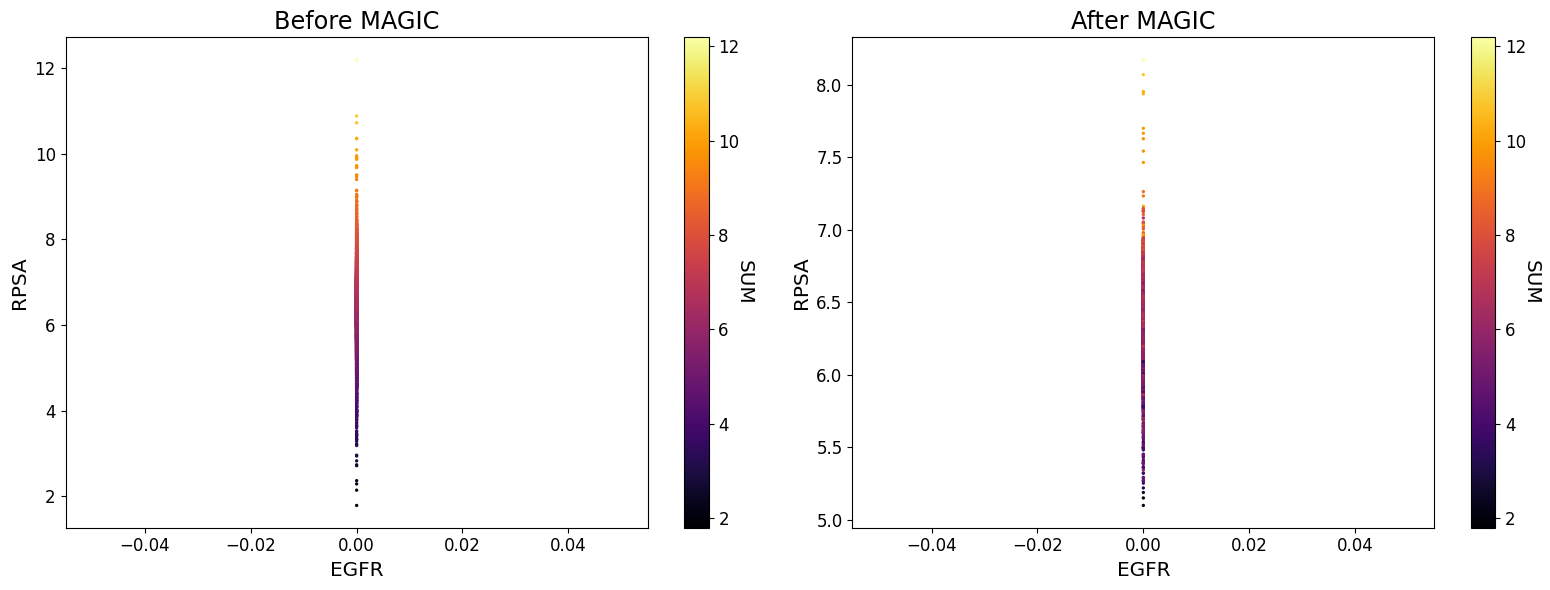

In [47]:
import matplotlib
import matplotlib.pyplot as plt

# Matplotlib command for Jupyter notebooks only
%matplotlib inline

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(16, 6))

scprep.plot.scatter(x=emt_data['EGFR'], y=emt_data['RPSA'], c=emt_data['EGFR']+emt_data['RPSA'],  ax=ax1,
                    xlabel='EGFR', ylabel='RPSA', legend_title="SUM", title='Before MAGIC')

scprep.plot.scatter(x=emt_magic['EGFR'], y=emt_magic['RPSA'], c=emt_magic['EGFR']+emt_data['RPSA'], ax=ax2,
                    xlabel='EGFR', ylabel='RPSA', legend_title="SUM", title='After MAGIC')

plt.tight_layout()
plt.show()

In [50]:
k562_cell_line_imputed = sc.AnnData(emt_magic)
k562_cell_line_imputed.var['gene_name'] = k562_cell_line_imputed.var.index.values
k562_cell_line_imputed.write_h5ad('./k562_cell_line_imputed.h5ad')

/home/yimiaofeng/anaconda3/envs/dotsl/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
